**Import libraries**

In [4]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [3]:
import cv2

print(cv2.__version__)
print(hasattr(cv2, "CascadeClassifier"))

4.10.0
True


**Set the dataset path**

In [6]:
import os
import cv2
import numpy as np

dataset_path = "../dataset/Pheany"

images = []
labels = []

for filename in os.listdir(dataset_path):

    if filename.endswith(".jpg"):

        image_path = os.path.join(dataset_path, filename)

        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        images.append(image)
        labels.append("Pheany")

images = np.array(images)
labels = np.array(labels)

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: (100, 64, 64)
Labels shape: (100,)


**Display some of my 100 images**

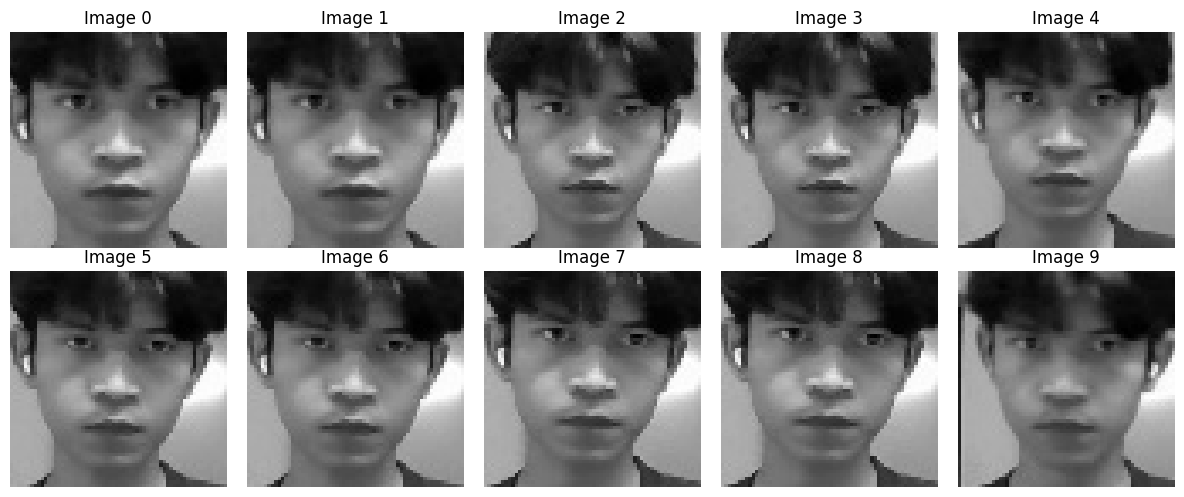

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Image {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Flatten the images**

In [8]:
X = images.reshape(images.shape[0], -1)

print("Original image shape:", images.shape)
print("Processed dataset shape:", X.shape)

Original image shape: (100, 64, 64)
Processed dataset shape: (100, 4096)


**Create the labels y**

In [9]:
y = np.array(["Pheany"] * len(images))

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Labels:", np.unique(y))

X shape: (100, 4096)
y shape: (100,)
Labels: ['Pheany']


In [10]:
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())
print("First 20 pixel values:")
print(X[0][:20])

Minimum pixel value: 25
Maximum pixel value: 255
First 20 pixel values:
[56 58 58 56 54 54 52 51 46 43 40 38 36 36 39 43 48 46 45 45]


In [11]:
y_numeric = np.zeros(len(images), dtype=int)

print("Labels:", y_numeric)
print("Unique labels:", np.unique(y_numeric))

Labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Unique labels: [0]


**Apply PCA to 100 face images**

In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50)

X_pca = pca.fit_transform(X)

print("Original shape:", X.shape)
print("PCA shape:", X_pca.shape)

Original shape: (100, 4096)
PCA shape: (100, 50)


**Check how much information PCA retained**

In [13]:
explained_variance = np.sum(pca.explained_variance_ratio_)

print(f"Variance retained: {explained_variance * 100:.2f}%")

Variance retained: 99.45%


**Visualize the Eigenfaces**

In [14]:
pca.components_

array([[-0.01863452, -0.02049188, -0.02020645, ..., -0.01342193,
        -0.01622992, -0.02151348],
       [-0.01175451, -0.00612162, -0.00783897, ...,  0.00026334,
        -0.00631971, -0.0061893 ],
       [ 0.08994954,  0.09375989,  0.08814126, ..., -0.04411958,
        -0.03776247, -0.0278203 ],
       ...,
       [-0.02916274,  0.0258855 , -0.03767659, ...,  0.0347474 ,
         0.01140871,  0.02169391],
       [ 0.00861767,  0.04623988, -0.00812386, ..., -0.00275619,
         0.04998215,  0.0673673 ],
       [ 0.02686919,  0.03486371,  0.00625268, ...,  0.01183298,
         0.00428666,  0.03473915]])

In [15]:
eigenfaces = pca.components_

print("Eigenfaces shape:", eigenfaces.shape)

Eigenfaces shape: (50, 4096)


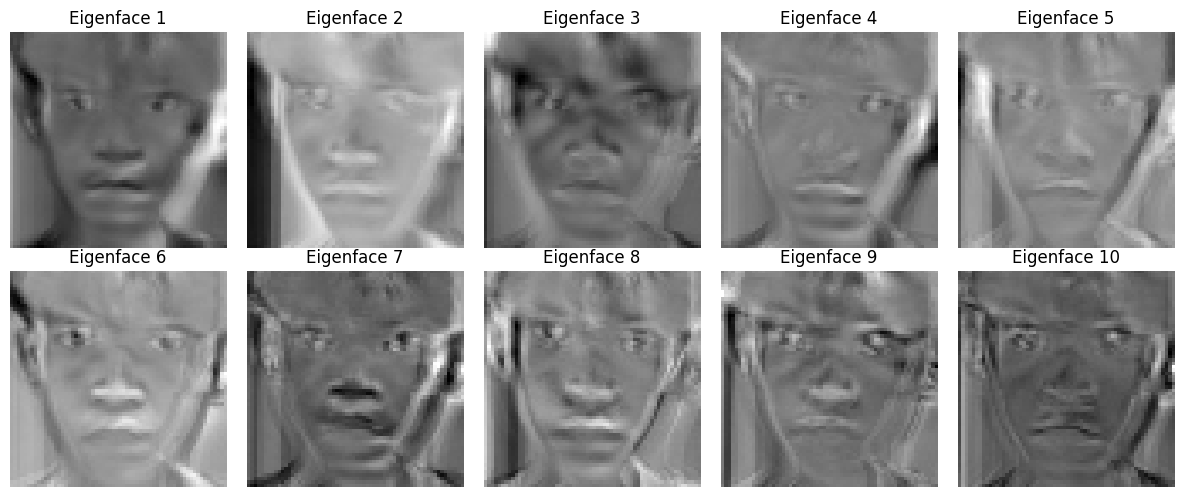

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(
        eigenfaces[i].reshape(64, 64),
        cmap="gray"
    )
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Plot the Explained Variance**

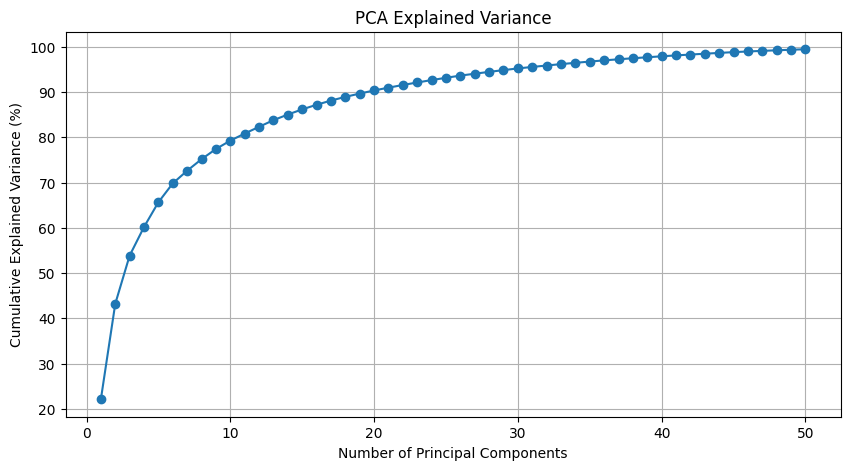

In [17]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.grid(True)

plt.show()

**Check reconstruction from PCA**

In [23]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50)

X_pca = pca.fit_transform(X)

print("Original shape:", X.shape)
print("PCA shape:", X_pca.shape)
print("Components shape:", pca.components_.shape)

Original shape: (100, 4096)
PCA shape: (100, 50)
Components shape: (50, 4096)


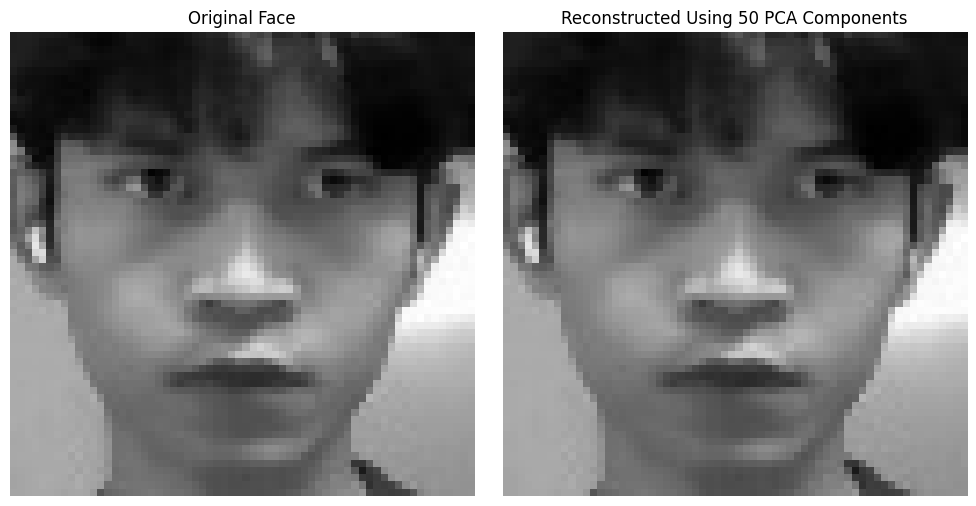

In [24]:
X_reconstructed = pca.inverse_transform(X_pca)

original_image = X[0].reshape(64, 64)
reconstructed_image = X_reconstructed[0].reshape(64, 64)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image, cmap="gray")
axes[0].set_title("Original Face")
axes[0].axis("off")

axes[1].imshow(reconstructed_image, cmap="gray")
axes[1].set_title("Reconstructed Using 50 PCA Components")
axes[1].axis("off")

plt.tight_layout()
plt.show()

**Other person**

In [25]:
from sklearn.datasets import fetch_olivetti_faces

olivetti = fetch_olivetti_faces()

print("Images shape:", olivetti.images.shape)
print("Labels shape:", olivetti.target.shape)

Images shape: (400, 64, 64)
Labels shape: (400,)


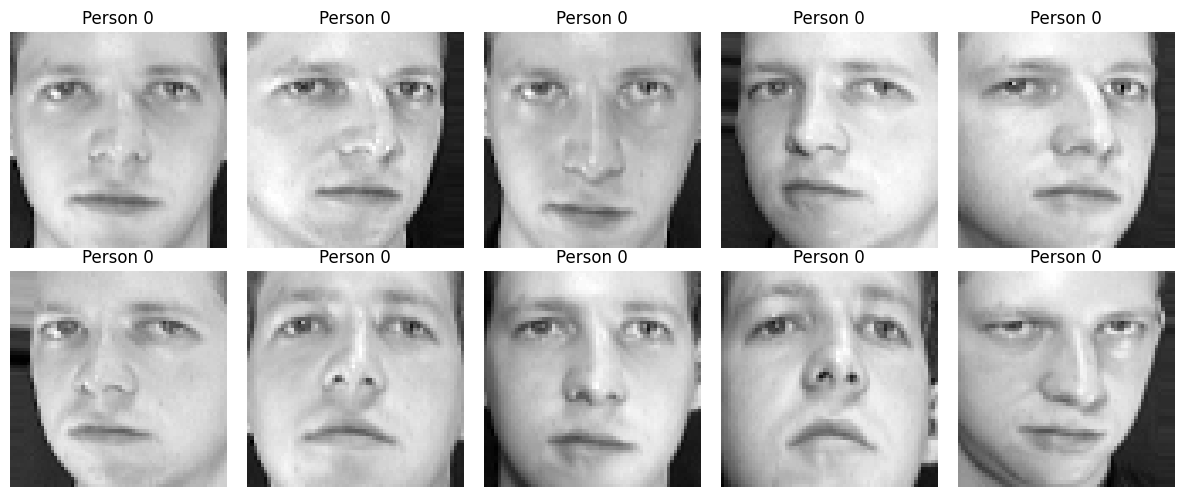

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(olivetti.images[i], cmap="gray")
    ax.set_title(f"Person {olivetti.target[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

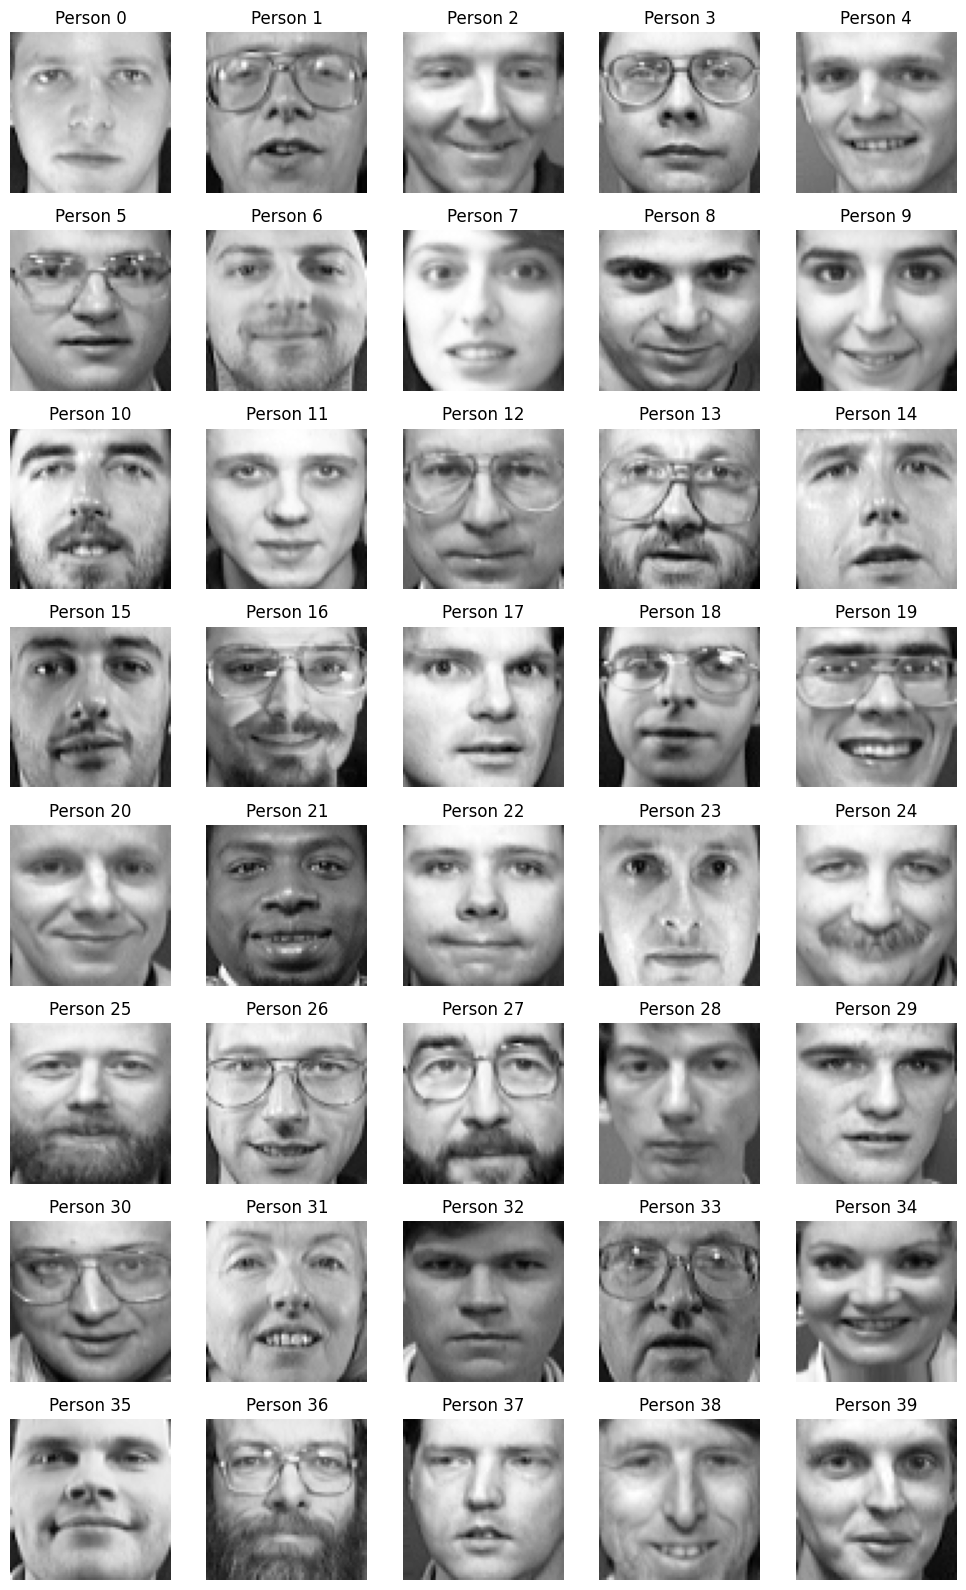

In [27]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(8, 5, figsize=(10, 16))

for person in range(40):
    # Take the first image of each person
    image = olivetti.images[person * 10]

    axes.ravel()[person].imshow(image, cmap="gray")
    axes.ravel()[person].set_title(f"Person {person}")
    axes.ravel()[person].axis("off")

plt.tight_layout()
plt.show()

**Create the Person2 folder**

In [31]:
import os
import cv2

# Olivetti person number → our project folder
people = {
    0: "Person2",
    2: "Person3",
    7: "Person4",
    9: "Person5"
}

for olivetti_person, folder_name in people.items():

    folder_path = os.path.join("../dataset", folder_name)
    os.makedirs(folder_path, exist_ok=True)

    # Each Olivetti person has 10 images
    start = olivetti_person * 10
    end = start + 10

    for i, index in enumerate(range(start, end)):
        image = olivetti.images[index]

        # Convert from 0–1 to 0–255
        image = (image * 255).astype("uint8")

        filename = os.path.join(folder_path, f"{i}.jpg")
        cv2.imwrite(filename, image)

    print(f"{folder_name}: 10 images saved")

Person2: 10 images saved
Person3: 10 images saved
Person4: 10 images saved
Person5: 10 images saved


**Make the dataset balanced**

In [32]:
import os
import cv2

person1_path = "../dataset/Person1"

files = [
    f for f in os.listdir(person1_path)
    if f.endswith(".jpg")
]

files.sort()

# Keep only the first 10 images
for file in files[10:]:
    os.remove(os.path.join(person1_path, file))

print("Person1 images:", len(os.listdir(person1_path)))

Person1 images: 10


In [33]:
import os

dataset_root = "../dataset"

for person in sorted(os.listdir(dataset_root)):
    person_path = os.path.join(dataset_root, person)

    if os.path.isdir(person_path):
        count = len([
            f for f in os.listdir(person_path)
            if f.endswith(".jpg")
        ])

        print(f"{person}: {count} images")

Person1: 10 images
Person2: 10 images
Person3: 10 images
Person4: 10 images
Person5: 10 images


In [34]:
import os
import cv2
import numpy as np

dataset_root = "../dataset"

images = []
labels = []

for person in sorted(os.listdir(dataset_root)):

    person_path = os.path.join(dataset_root, person)

    if not os.path.isdir(person_path):
        continue

    for filename in sorted(os.listdir(person_path)):

        if filename.endswith(".jpg"):

            image_path = os.path.join(person_path, filename)

            image = cv2.imread(
                image_path,
                cv2.IMREAD_GRAYSCALE
            )

            # Make sure every image is 64 × 64
            image = cv2.resize(image, (64, 64))

            images.append(image)
            labels.append(person)

images = np.array(images)
labels = np.array(labels)

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("People:", np.unique(labels))

Images shape: (50, 64, 64)
Labels shape: (50,)
People: ['Person1' 'Person2' 'Person3' 'Person4' 'Person5']


In [35]:
X = images.reshape(images.shape[0], -1)
y = labels

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique people:", np.unique(y))

X shape: (50, 4096)
y shape: (50,)
Unique people: ['Person1' 'Person2' 'Person3' 'Person4' 'Person5']


**Split the dataset into training and testing data**

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (35, 4096)
Testing data: (15, 4096)
Training labels: (35,)
Testing labels: (15,)


**Train the SVM without PCA**

In [37]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Create SVM model
svm_no_pca = SVC(kernel="rbf")

# Train using the original 4096 features
svm_no_pca.fit(X_train, y_train)

# Predict the test faces
y_pred_no_pca = svm_no_pca.predict(X_test)

# Calculate accuracy
accuracy_no_pca = accuracy_score(y_test, y_pred_no_pca)

print(f"Accuracy without PCA: {accuracy_no_pca * 100:.2f}%")

Accuracy without PCA: 93.33%


In [38]:
print("Actual labels:   ", y_test)
print("Predicted labels:", y_pred_no_pca)

Actual labels:    ['Person2' 'Person1' 'Person4' 'Person1' 'Person3' 'Person3' 'Person3'
 'Person2' 'Person2' 'Person5' 'Person5' 'Person4' 'Person4' 'Person1'
 'Person5']
Predicted labels: ['Person2' 'Person1' 'Person4' 'Person1' 'Person3' 'Person3' 'Person3'
 'Person2' 'Person2' 'Person5' 'Person5' 'Person4' 'Person4' 'Person1'
 'Person4']


**Train the SVM with PCA**

In [39]:
from sklearn.decomposition import PCA

pca = PCA(n_components=10)

# Learn PCA only from training data
X_train_pca = pca.fit_transform(X_train)

# Transform test data using the same PCA
X_test_pca = pca.transform(X_test)

print("Original training shape:", X_train.shape)
print("PCA training shape:", X_train_pca.shape)

print("Original testing shape:", X_test.shape)
print("PCA testing shape:", X_test_pca.shape)

Original training shape: (35, 4096)
PCA training shape: (35, 10)
Original testing shape: (15, 4096)
PCA testing shape: (15, 10)


**Check how much information 10 components retain**

In [41]:
variance_10 = np.sum(pca.explained_variance_ratio_)

print(f"Variance retained: {variance_10 * 100:.2f}%")

Variance retained: 88.60%


**Train SVM on the PCA data**

In [42]:
svm_pca = SVC(kernel="rbf")

svm_pca.fit(X_train_pca, y_train)

y_pred_pca = svm_pca.predict(X_test_pca)

accuracy_pca = accuracy_score(y_test, y_pred_pca)

print(f"Accuracy with PCA: {accuracy_pca * 100:.2f}%")

Accuracy with PCA: 93.33%


**Compare the two models**

In [43]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Without PCA",
        "With PCA"
    ],
    "Features": [
        X_train.shape[1],
        X_train_pca.shape[1]
    ],
    "Accuracy (%)": [
        accuracy_no_pca * 100,
        accuracy_pca * 100
    ]
})

comparison

,Model,Features,Accuracy (%)
0,Without PCA,4096,93.333333
1,With PCA,10,93.333333


**Calculate the feature reduction**

In [44]:
reduction = (
    1 - X_train_pca.shape[1] / X_train.shape[1]
) * 100

print(f"Feature reduction: {reduction:.2f}%")

Feature reduction: 99.76%


**Confusion matrix  Without PCA**

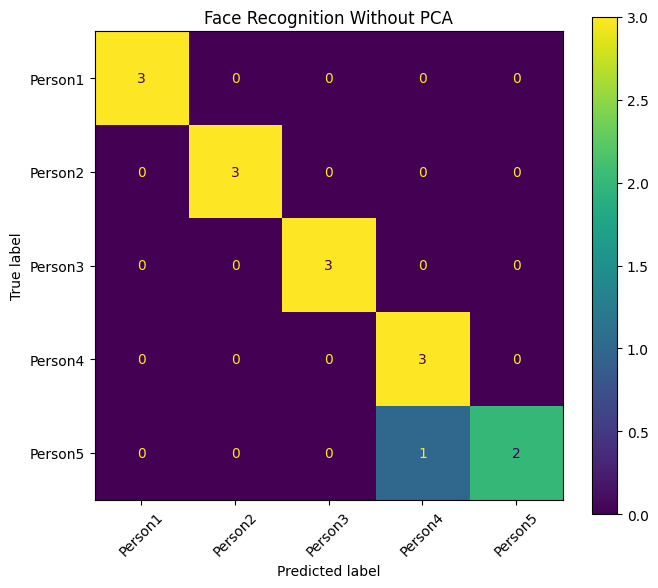

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_no_pca = confusion_matrix(
    y_test,
    y_pred_no_pca,
    labels=np.unique(y)
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_no_pca,
    display_labels=np.unique(y)
)

disp.plot(ax=ax, xticks_rotation=45)
ax.set_title("Face Recognition Without PCA")

plt.tight_layout()
plt.show()

**Confusion matrix  With PCA**

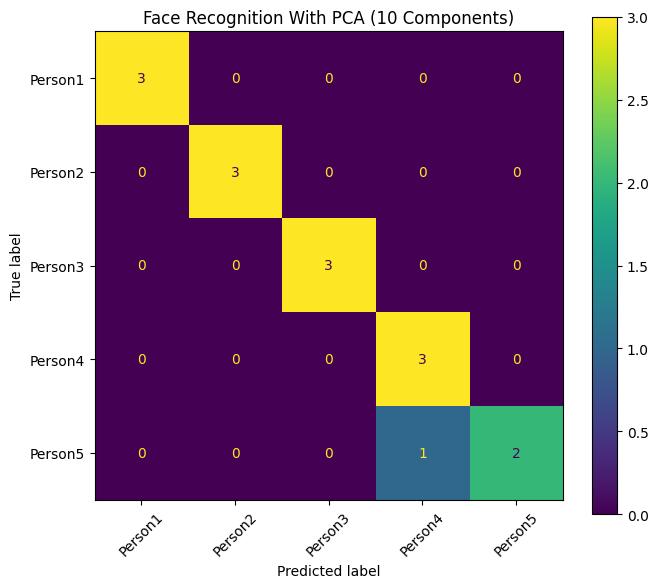

In [46]:
cm_pca = confusion_matrix(
    y_test,
    y_pred_pca,
    labels=np.unique(y)
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_pca,
    display_labels=np.unique(y)
)

disp.plot(ax=ax, xticks_rotation=45)
ax.set_title("Face Recognition With PCA (10 Components)")

plt.tight_layout()
plt.show()

**Test different numbers of PCA components**

In [47]:
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

pca_components = [2, 5, 10, 15, 20, 25, 30]

results = []

for n in pca_components:

    # PCA
    pca_temp = PCA(n_components=n)

    X_train_temp = pca_temp.fit_transform(X_train)
    X_test_temp = pca_temp.transform(X_test)

    # SVM
    svm_temp = SVC(kernel="rbf")

    svm_temp.fit(X_train_temp, y_train)

    y_pred_temp = svm_temp.predict(X_test_temp)

    # Accuracy
    accuracy_temp = accuracy_score(
        y_test,
        y_pred_temp
    )

    # Explained variance
    variance_temp = np.sum(
        pca_temp.explained_variance_ratio_
    )

    results.append({
        "PCA Components": n,
        "Accuracy (%)": accuracy_temp * 100,
        "Variance Retained (%)": variance_temp * 100
    })

results_df = pd.DataFrame(results)

results_df

,PCA Components,Accuracy (%),Variance Retained (%)
0,2,46.666667,60.495066
1,5,86.666667,78.054352
2,10,93.333333,88.599057
3,15,93.333333,93.510273
4,20,93.333333,96.531904
5,25,93.333333,98.491444
6,30,93.333333,99.707245


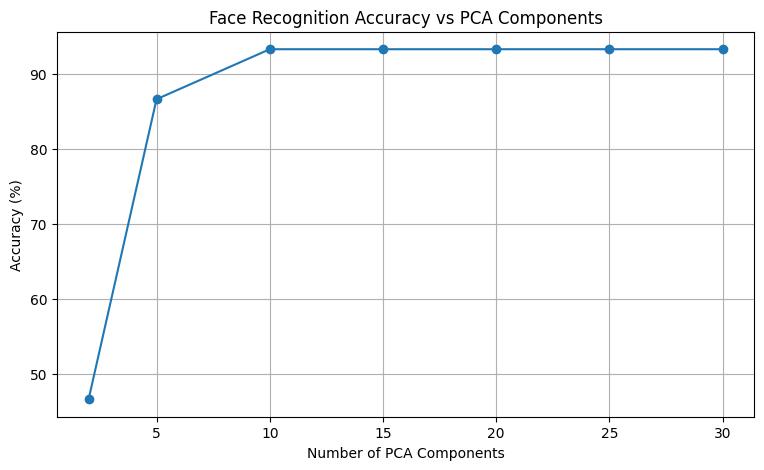

In [48]:
plt.figure(figsize=(9, 5))

plt.plot(
    results_df["PCA Components"],
    results_df["Accuracy (%)"],
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Accuracy vs PCA Components")
plt.grid(True)

plt.show()

**Measure SVM without PCA**

In [49]:
import time
from sklearn.svm import SVC

# Start timer
start_train = time.time()

svm_no_pca = SVC(kernel="rbf")
svm_no_pca.fit(X_train, y_train)

train_time_no_pca = time.time() - start_train


# Prediction time
start_predict = time.time()

y_pred_no_pca = svm_no_pca.predict(X_test)

predict_time_no_pca = time.time() - start_predict


print(f"Training time without PCA: {train_time_no_pca:.6f} seconds")
print(f"Prediction time without PCA: {predict_time_no_pca:.6f} seconds")

Training time without PCA: 0.003002 seconds
Prediction time without PCA: 0.001998 seconds


**Measure SVM with PCA**

In [50]:
from sklearn.decomposition import PCA

# PCA
pca_time = PCA(n_components=10)

X_train_pca = pca_time.fit_transform(X_train)
X_test_pca = pca_time.transform(X_test)


# Train SVM
start_train = time.time()

svm_pca = SVC(kernel="rbf")
svm_pca.fit(X_train_pca, y_train)

train_time_pca = time.time() - start_train


# Prediction
start_predict = time.time()

y_pred_pca = svm_pca.predict(X_test_pca)

predict_time_pca = time.time() - start_predict


print(f"Training time with PCA: {train_time_pca:.6f} seconds")
print(f"Prediction time with PCA: {predict_time_pca:.6f} seconds")

Training time with PCA: 0.001003 seconds
Prediction time with PCA: 0.000696 seconds


**Comparison table**

In [51]:
time_comparison = pd.DataFrame({
    "Model": [
        "Without PCA",
        "With PCA"
    ],
    "Features": [
        X_train.shape[1],
        X_train_pca.shape[1]
    ],
    "Training Time (s)": [
        train_time_no_pca,
        train_time_pca
    ],
    "Prediction Time (s)": [
        predict_time_no_pca,
        predict_time_pca
    ]
})

time_comparison

,Model,Features,Training Time (s),Prediction Time (s)
0,Without PCA,4096,0.003002,0.001998
1,With PCA,10,0.001003,0.000696


**Precision, Recall, and F1-score**

In [52]:
from sklearn.metrics import classification_report

print("===== WITHOUT PCA =====")

print(
    classification_report(
        y_test,
        y_pred_no_pca
    )
)

===== WITHOUT PCA =====
              precision    recall  f1-score   support

     Person1       1.00      1.00      1.00         3
     Person2       1.00      1.00      1.00         3
     Person3       1.00      1.00      1.00         3
     Person4       0.75      1.00      0.86         3
     Person5       1.00      0.67      0.80         3

    accuracy                           0.93        15
   macro avg       0.95      0.93      0.93        15
weighted avg       0.95      0.93      0.93        15



In [53]:
print("===== WITH PCA =====")

print(
    classification_report(
        y_test,
        y_pred_pca
    )
)

===== WITH PCA =====
              precision    recall  f1-score   support

     Person1       1.00      1.00      1.00         3
     Person2       1.00      1.00      1.00         3
     Person3       1.00      1.00      1.00         3
     Person4       0.75      1.00      0.86         3
     Person5       1.00      0.67      0.80         3

    accuracy                           0.93        15
   macro avg       0.95      0.93      0.93        15
weighted avg       0.95      0.93      0.93        15



**Final comparison table**

In [54]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Metrics for model without PCA
precision_no_pca = precision_score(
    y_test, y_pred_no_pca, average="weighted", zero_division=0
)

recall_no_pca = recall_score(
    y_test, y_pred_no_pca, average="weighted", zero_division=0
)

f1_no_pca = f1_score(
    y_test, y_pred_no_pca, average="weighted", zero_division=0
)


# Metrics for model with PCA
precision_pca = precision_score(
    y_test, y_pred_pca, average="weighted", zero_division=0
)

recall_pca = recall_score(
    y_test, y_pred_pca, average="weighted", zero_division=0
)

f1_pca = f1_score(
    y_test, y_pred_pca, average="weighted", zero_division=0
)


# Final comparison
final_comparison = pd.DataFrame({
    "Model": [
        "Without PCA",
        "With PCA"
    ],
    "Features": [
        X_train.shape[1],
        X_train_pca.shape[1]
    ],
    "Accuracy (%)": [
        accuracy_score(y_test, y_pred_no_pca) * 100,
        accuracy_score(y_test, y_pred_pca) * 100
    ],
    "Precision": [
        precision_no_pca,
        precision_pca
    ],
    "Recall": [
        recall_no_pca,
        recall_pca
    ],
    "F1-score": [
        f1_no_pca,
        f1_pca
    ],
    "Training Time (s)": [
        train_time_no_pca,
        train_time_pca
    ],
    "Prediction Time (s)": [
        predict_time_no_pca,
        predict_time_pca
    ]
})

final_comparison

,Model,Features,Accuracy (%),Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Without PCA,4096,93.333333,0.95,0.933333,0.931429,0.003002,0.001998
1,With PCA,10,93.333333,0.95,0.933333,0.931429,0.001003,0.000696


**Accuracy: With PCA vs Without PCA**

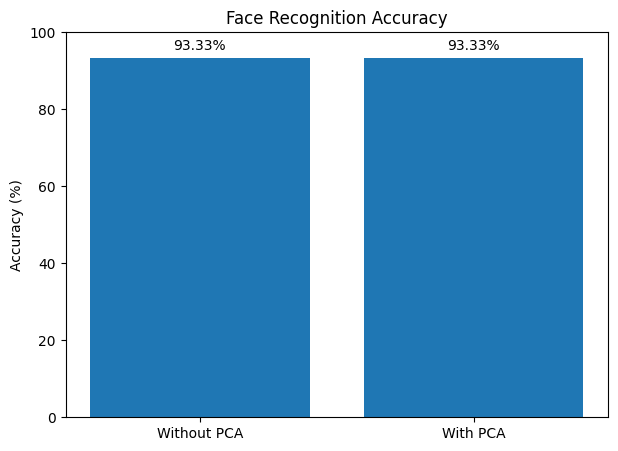

In [55]:
plt.figure(figsize=(7, 5))

models = ["Without PCA", "With PCA"]
accuracies = [
    accuracy_no_pca * 100,
    accuracy_pca * 100
]

plt.bar(models, accuracies)

plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Accuracy")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 2, f"{value:.2f}%", ha="center")

plt.show()

**Feature reduction**

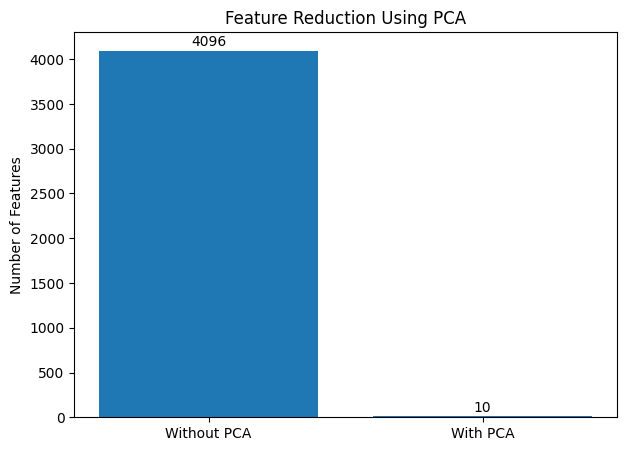

In [56]:
plt.figure(figsize=(7, 5))

features = [X_train.shape[1], X_train_pca.shape[1]]
models = ["Without PCA", "With PCA"]

plt.bar(models, features)

plt.ylabel("Number of Features")
plt.title("Feature Reduction Using PCA")

for i, value in enumerate(features):
    plt.text(i, value + 50, str(value), ha="center")

plt.show()

**Plot PCA components vs. explained variance**

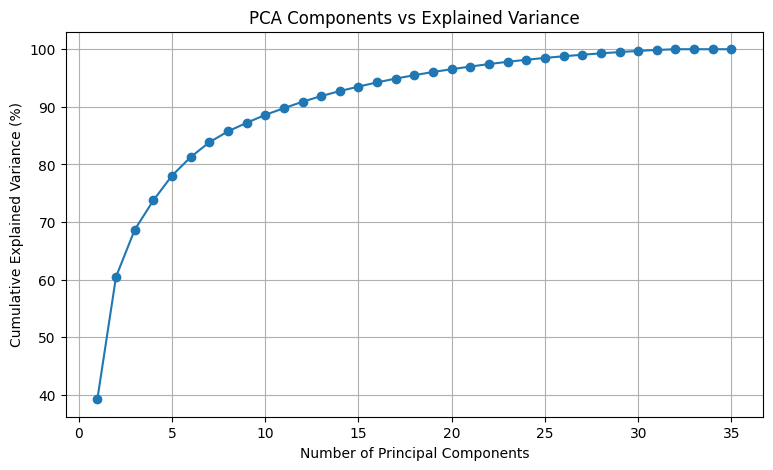

In [57]:
# Fit PCA with all possible components from the training data
pca_full = PCA()

X_train_full = pca_full.fit_transform(X_train)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Components vs Explained Variance")
plt.grid(True)

plt.show()

**Plot PCA Components vs Accuracy and Explained Variance**

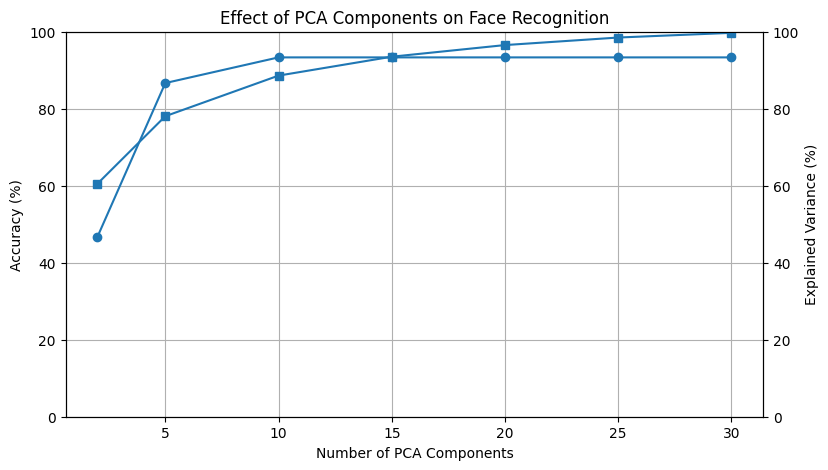

In [58]:
fig, ax1 = plt.subplots(figsize=(9, 5))

# Accuracy
ax1.plot(
    results_df["PCA Components"],
    results_df["Accuracy (%)"],
    marker="o",
    label="Accuracy"
)

ax1.set_xlabel("Number of PCA Components")
ax1.set_ylabel("Accuracy (%)")
ax1.set_ylim(0, 100)
ax1.grid(True)

# Explained variance
ax2 = ax1.twinx()

ax2.plot(
    results_df["PCA Components"],
    results_df["Variance Retained (%)"],
    marker="s",
    label="Explained Variance"
)

ax2.set_ylabel("Explained Variance (%)")
ax2.set_ylim(0, 100)

plt.title("Effect of PCA Components on Face Recognition")

plt.show()

**Save the trained PCA and SVM models**

In [59]:
import joblib

# Save PCA model
joblib.dump(pca, "../models/pca_model.pkl")

# Save SVM model
joblib.dump(svm_pca, "../models/svm_pca_model.pkl")

print("PCA model saved.")
print("SVM model saved.")

PCA model saved.
SVM model saved.
